In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("titanic.csv")

print("Titanic dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Titanic dataset loaded successfully!
Dataset shape: (887, 8)


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [3]:

# Check dataset information
print("DATASET INFORMATION")
df.info()

# Check for missing values
print("\nMISSING VALUES")
print(df.isnull().sum())

# View summary statistics
print("\nSUMMARY STATISTICS")
display(df.describe())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Survived                 887 non-null    int64  
 1   Pclass                   887 non-null    int64  
 2   Name                     887 non-null    object 
 3   Sex                      887 non-null    object 
 4   Age                      887 non-null    float64
 5   Siblings/Spouses Aboard  887 non-null    int64  
 6   Parents/Children Aboard  887 non-null    int64  
 7   Fare                     887 non-null    float64
dtypes: float64(2), int64(4), object(2)
memory usage: 55.6+ KB

MISSING VALUES
Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64

SUMMARY STA

,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


              Age       Fare
count  887.000000  887.00000
mean    29.471443   32.30542
std     14.121908   49.78204
min      0.420000    0.00000
25%     20.250000    7.92500
50%     28.000000   14.45420
75%     38.000000   31.13750
max     80.000000  512.32920


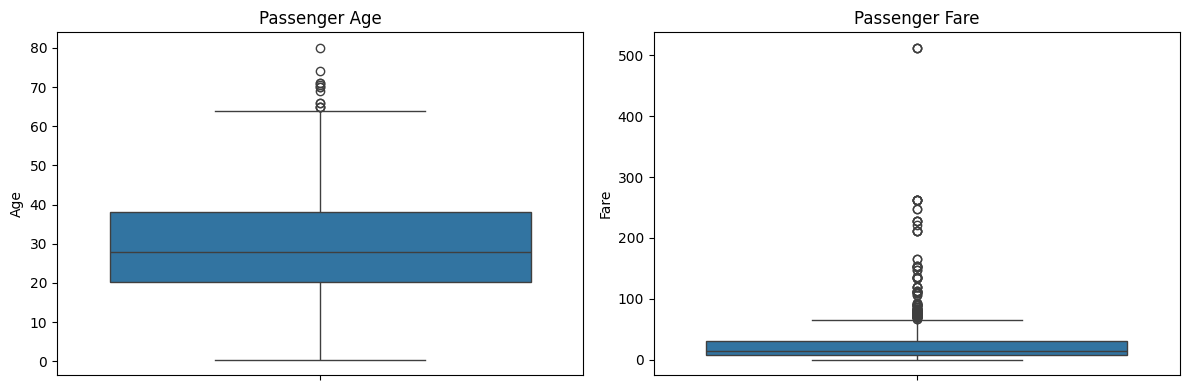

In [4]:

# Check statistics for Age and Fare
print(df[["Age", "Fare"]].describe())

# Create boxplots to identify possible outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(y=df["Age"], ax=axes[0])
axes[0].set_title("Passenger Age")

sns.boxplot(y=df["Fare"], ax=axes[1])
axes[1].set_title("Passenger Fare")

plt.tight_layout()
plt.show()


SURVIVAL RATE BY SEX
Sex
female    74.203822
male      19.022688
Name: Survived, dtype: float64

SURVIVAL RATE BY CLASS
Pclass
1    62.962963
2    47.282609
3    24.435318
Name: Survived, dtype: float64


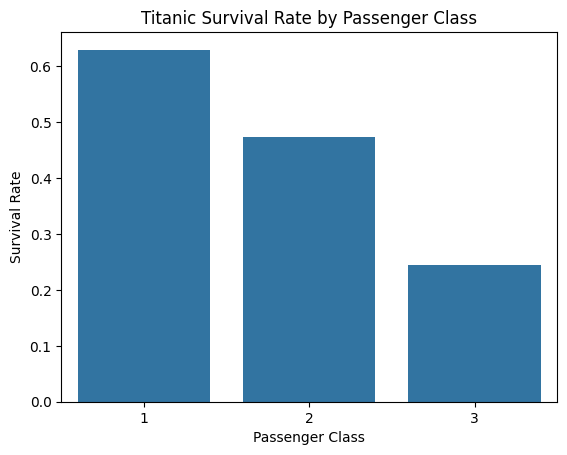

In [5]:

# Survival rate by sex
print("SURVIVAL RATE BY SEX")
print(df.groupby("Sex")["Survived"].mean() * 100)

# Survival rate by passenger class
print("\nSURVIVAL RATE BY CLASS")
print(df.groupby("Pclass")["Survived"].mean() * 100)

# Visualize survival by class
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)
plt.title("Titanic Survival Rate by Passenger Class")
plt.ylabel("Survival Rate")
plt.xlabel("Passenger Class")
plt.show()


In [6]:

# Select passenger features
X = df[[
    "Pclass",
    "Sex",
    "Age",
    "Siblings/Spouses Aboard",
    "Parents/Children Aboard",
    "Fare"
]]

# Convert Sex into numeric columns
X = pd.get_dummies(X, columns=["Sex"], drop_first=True, dtype=int)

# Select target
y = df["Survived"]

print("FEATURES")
display(X.head())

print("TARGET")
display(y.head())


FEATURES


,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,Sex_male
0,3,22.0,1,0,7.2500,1
1,1,38.0,1,0,71.2833,0
2,3,26.0,0,0,7.9250,0
3,1,35.0,1,0,53.1000,0
4,3,35.0,0,0,8.0500,1


TARGET


,Survived
0,0
1,1
2,1
3,1
4,0


In [7]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create and train the model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

print("Titanic logistic regression model trained successfully!")
print("Training passengers:", len(X_train))
print("Testing passengers:", len(X_test))


Titanic logistic regression model trained successfully!
Training passengers: 709
Testing passengers: 178


MODEL EVALUATION
Accuracy: 0.7697
Precision: 0.7121
Recall: 0.6812
F1 Score: 0.6963

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       109
           1       0.71      0.68      0.70        69

    accuracy                           0.77       178
   macro avg       0.76      0.75      0.76       178
weighted avg       0.77      0.77      0.77       178



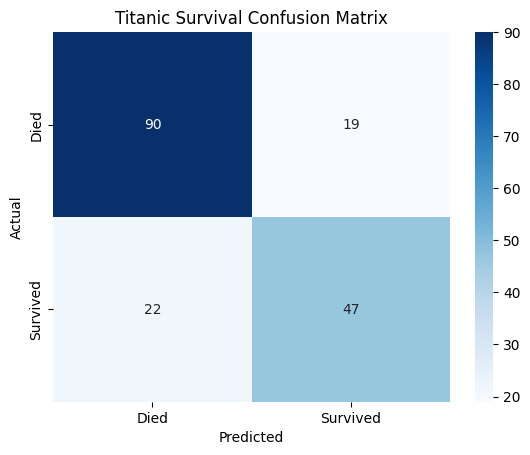

In [8]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict survival for testing passengers
y_pred = model.predict(X_test)

# Evaluate model performance
print("MODEL EVALUATION")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))

# Display classification report
print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Died", "Survived"],
            yticklabels=["Died", "Survived"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Titanic Survival Confusion Matrix")
plt.show()
